# Price-path risk analysis — daily-close scenarios

Four models independently generate future closing-price paths. All models share **threshold-event probabilities**, return quantiles, whole-path extreme ranges, and post-decline recovery statistics; no results call regenerates paths.

**Primary results:** `threshold_probabilities()` gives the probability that the H-th terminal price, the lowest future close, or the highest future close is above/below a selected threshold. This is **not** a table of mutually exclusive intervals: columns can overlap and need not sum to 100%.

**Quantile and path-range results:** `extreme_range()` computes boundaries within which at least the requested fraction of modeled **whole daily-close paths** stays, over each stated horizon. `empirical_coverage` refers to the modeled paths, not guaranteed future market coverage.

All values use **daily closes**, not intraday prices. The known as-of close is excluded from future-close observations. Monte Carlo results rely on model assumptions; historical results rely on the sampled periods and can have overlapping, dependent observations.

**Setup:** `pip install numpy pandas scipy matplotlib finance-datareader jupyter`. Keep this notebook and `price_target_analysis.py` together. Check data-provider conventions for adjusted closes, corporate actions and ETF distributions.

## 0. Shared setup and price data

- `symbol`: `KS11` (KOSPI), `KS200` (KOSPI 200), `069500` (KODEX 200 ETF), `005930` (Samsung Electronics), etc.
- `as_of_date=None` selects the latest close **in the loaded data**; it does not fetch a live quotation.
- `horizon_days` is the maximum number of future trading sessions for all model outputs.
- `thresholds=[-10, 10]`, with `pct=True`, means changes of -10% and +10% relative to the as-of close; with `pct=False`, thresholds represent absolute price/index levels.
- `mode='mixed'` applies strict `<` below the starting price and inclusive `≥` at or above it. Choose `above` or `below` to apply one direction to every threshold.
- `price_type='terminal'` evaluates the final daily close. `min` and `max` evaluate the lowest or highest **future** daily close, respectively. These provide close-based barrier events when combined with `min/below` or `max/above`.

Optional distribution charts display fixed-width percentage-return bins; they do not replace threshold probabilities.

In [1]:
from price_target_analysis import (
    PriceTargetAnalysis, AsOfCriterion, FixedValueCriterion,
    ModelComparison, load_prices,
)

In [6]:
symbol = "KS11"
#symbol = "KQ11"
history_start = "2001-01-01"
as_of_date = None
horizon_days = 21

In [7]:
prices = load_prices(symbol, start=history_start, end=as_of_date, cache_dir="data", refresh=False)

In [8]:
analysis = PriceTargetAnalysis(prices, as_of_date=as_of_date, horizon_days=horizon_days)

In [9]:
analysis.info()

as_of_date: 2026-11-17
reference_price: 4968
horizon_days: 21
available_start: 2001-01-02
available_closes: 6382


## 1. Normal IID log returns with realized volatility

**Purpose — a volatility-risk baseline, not a directional forecast.** The model estimates volatility from each `lookback_days` window and simulates IID Gaussian log returns with zero drift. Variants share the same random shocks to isolate volatility sensitivity. Overlapping lookback windows do not provide independent evidence.

**Interpretation:**

1. Use `normal.summary()` to compare annualized volatility estimates.
2. Use `threshold_probabilities()` to compare the probability of a **fixed downside threshold** across lookback variants, rather than comparing upside and downside probabilities as directional forecasts.
3. Use `extreme_range()` to compare price ranges containing the specified proportion of **entire future daily-close paths**, not just terminal prices.

**Limitations:** Zero log drift imposes symmetric log-return movements but not symmetric price changes or zero expected arithmetic returns. Apparent upside/downside differences therefore do not establish a directional market view. Results are model-conditional estimates, not calibrated real-world probabilities, and simulated paths are not independent historical observations.

Expected Shortfall and decline-then-recovery probabilities are outside the current scope.

In [10]:
normal = analysis.normal(
    lookback_days=[20, 60, 120], simulations=20_000, random_seed=42,
)
normal.summary()

,status,n_paths,as_of_date,reference_price,horizon_days,lookback_days,annualized_volatility,annual_log_drift,simulations
variant,,,,,,,,,
20d_vol,ok,20000,2026-11-17,4968,21,20,0.537667,0.0,20000
60d_vol,ok,20000,2026-11-17,4968,21,60,0.455209,0.0,20000
120d_vol,ok,20000,2026-11-17,4968,21,120,0.643561,0.0,20000


In [11]:
kw = dict(
    thresholds=[-10, -5, 5, 10], pct=True
)
normal.threshold_probabilities(mode="mixed", **kw)

as_of_date 2026-11-17, reference_price 4968, horizon_days 21


,<-10%,<-5%,≥+5%,≥+10%
variant,,,,
20d_vol,25.1%,37.3%,37.5%,27.0%
60d_vol,21.2%,35.0%,35.4%,23.6%
120d_vol,28.9%,39.2%,39.5%,30.4%


In [14]:
# `price_type='min', mode='below'` reports whether the *lowest future daily close* breached the specified downside thresholds.
normal.threshold_probabilities(mode="below", price_type="min", **kw)
#normal.threshold_probabilities(mode="above", price_type="max", **kw)

as_of_date 2026-11-17, reference_price 4968, horizon_days 21


,<-10%,<-5%,<+5%,<+10%
variant,,,,
20d_vol,42.9%,65.5%,98.8%,100.0%
60d_vol,36.0%,61.3%,99.3%,100.0%
120d_vol,49.7%,69.4%,98.0%,99.9%


In [17]:
normal.return_quantiles(probabilities=[0.1, 0.25, 0.5, 0.75, 0.9])

as_of_date 2026-11-17, reference_price 4968, horizon_days 21


,p10,p25,p50,p75,p90
variant,,,,,
20d_vol,-17.9%,-10.0%,-0.0%,+11.1%,+22.1%
60d_vol,-15.4%,-8.6%,-0.0%,+9.3%,+18.4%
120d_vol,-21.1%,-11.9%,-0.0%,+13.5%,+26.9%


In [18]:
normal.extreme_range(probability=0.9)

as_of_date 2026-11-17, reference_price 4968, horizon_days 21


,variant,horizon_days,probability,lower_price,upper_price,empirical_coverage,n_paths,status,warning
0,20d_vol,21,0.9,3736.518334,6619.478192,0.9,20000,ok,None
1,60d_vol,21,0.9,3903.434274,6334.532909,0.9,20000,ok,None
2,120d_vol,21,0.9,3532.589787,7004.285622,0.9,20000,ok,None


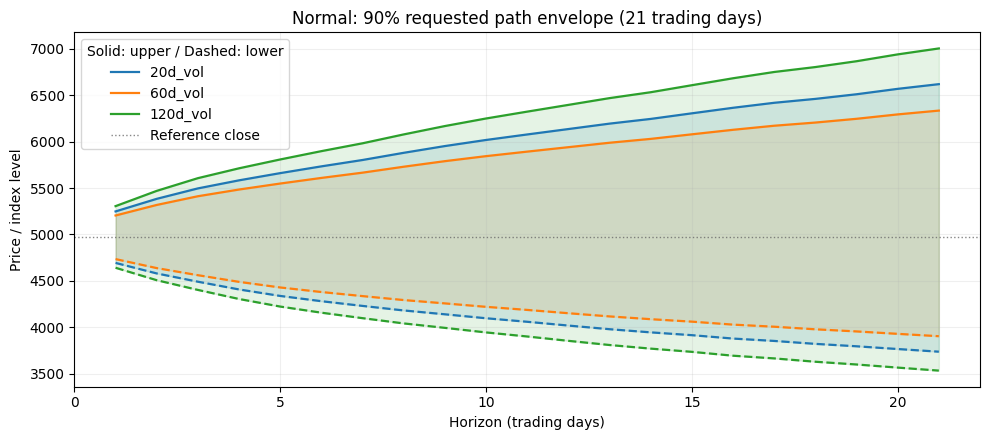

In [19]:
normal.plot_extreme_range(probability=0.9)

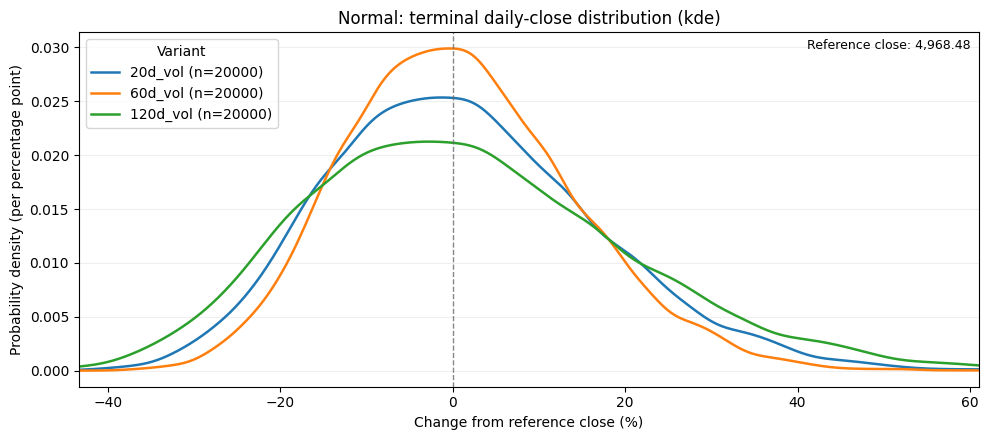

In [20]:
normal.plot_price_distribution(kind='kde')

In [21]:
normal.recovery_after_decline(decline_pct=5)

as_of_date 2026-11-17, reference_price 4968, horizon_days 21


,horizon_days,decline_pct,recovery_pct,n_paths,decline_paths,recovered_paths,decline_probability_pct,recovery_probability_pct,median_recovery_days,status,warning
variant,,,,,,,,,,,
20d_vol,21,5.0%,0.0%,20000,13102,6187,65.5%,47.2%,5.0,ok,—
60d_vol,21,5.0%,0.0%,20000,12254,5098,61.3%,41.6%,6.0,ok,—
120d_vol,21,5.0%,0.0%,20000,13884,7236,69.4%,52.1%,5.0,ok,—


## 2. Historical empirical paths

For each eligible historical start date (`sampling_step=1` means every trading day), observe the following `horizon_days` actual closing prices. Express each path relative to its starting close, then scale it to the current reference price. Overlapping historical windows are dependent observations; the path count should not be treated as an independent sample size.


In [23]:
empirical = analysis.empirical(history_start=history_start, sampling_step=1, min_history_days=252, min_samples=30)
empirical.summary()

,status,n_paths,as_of_date,reference_price,horizon_days,available_paths,min_samples,first_start,last_start,sampling_step,available_history_days,min_history_days
variant,,,,,,,,,,,,
historical,ok,6361,2026-11-17,4968,21,6361,30,2001-01-02,2026-10-19,1,6382,252


In [24]:
kw = dict(
    thresholds=[-10, -5, 5, 10], pct=True
)
empirical.threshold_probabilities(mode="mixed", **kw)

as_of_date 2026-11-17, reference_price 4968, horizon_days 21


,<-10%,<-5%,≥+5%,≥+10%
variant,,,,
historical,4.8%,13.6%,22.9%,6.8%


In [29]:
# `price_type='min', mode='below'` reports whether the *lowest future daily close* breached the specified downside thresholds.
#empirical.threshold_probabilities(mode="below", price_type="min", **kw)
empirical.threshold_probabilities(mode="above", price_type="terminal", **kw)

as_of_date 2026-11-17, reference_price 4968, horizon_days 21


,≥-10%,≥-5%,≥+5%,≥+10%
variant,,,,
historical,95.2%,86.4%,22.9%,6.8%


In [30]:
empirical.return_quantiles(probabilities=[0.1, 0.25, 0.5, 0.75, 0.9])

as_of_date 2026-11-17, reference_price 4968, horizon_days 21


,p10,p25,p50,p75,p90
variant,,,,,
historical,-6.4%,-2.6%,+1.0%,+4.6%,+8.3%


In [32]:
empirical.extreme_range(probability=0.9)

as_of_date 2026-11-17, reference_price 4968, horizon_days 21


,variant,horizon_days,probability,lower_price,upper_price,empirical_coverage,n_paths,status,warning
0,historical,21,0.9,4326.682121,5604.213024,0.900016,6361,ok,None


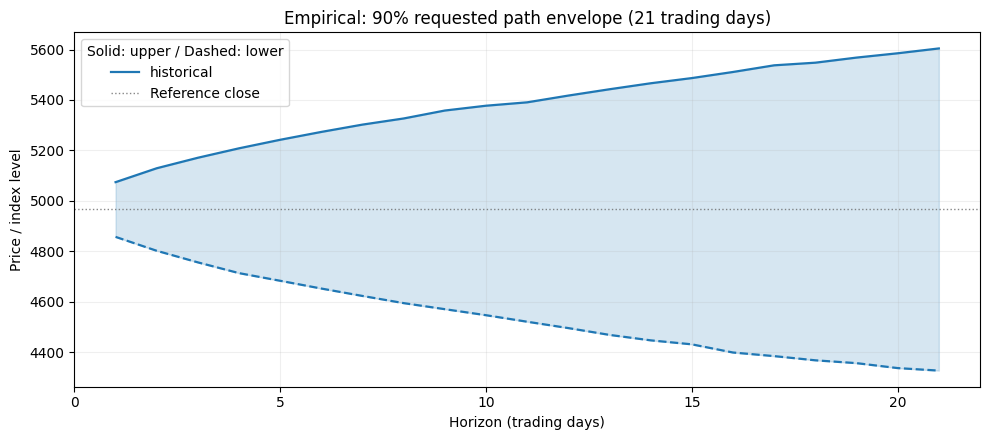

In [33]:
empirical.plot_extreme_range(probability=0.9)

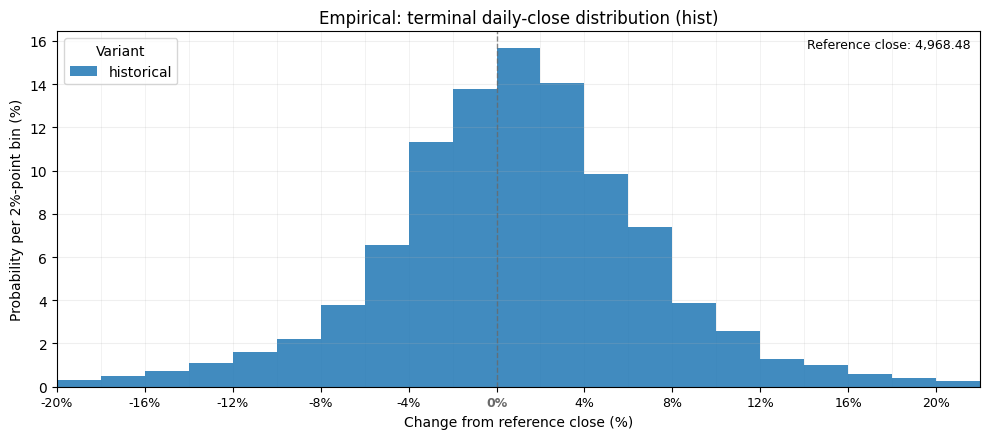

In [34]:
empirical.plot_price_distribution(bin_width_pct=2)

In [35]:
empirical.recovery_after_decline(decline_pct=10)

as_of_date 2026-11-17, reference_price 4968, horizon_days 21


,horizon_days,decline_pct,recovery_pct,n_paths,decline_paths,recovered_paths,decline_probability_pct,recovery_probability_pct,median_recovery_days,status,warning
variant,,,,,,,,,,,
historical,21,10.0%,0.0%,6361,570,49,9.0%,8.6%,10.0,ok,—


## 3. Bootstrap

Resample historical daily log returns with replacement to construct simulated paths. `block_size=1` is the ordinary independent (IID) bootstrap; larger sizes such as 5, 10, and 20 draw consecutive return blocks and retain some short-run dependence within each block. `drift_adjustment="none"` retains the historical mean log return; `"zero"` subtracts it. Hold other parameters fixed when assessing the effect of block length.


In [36]:
bootstrap = analysis.bootstrap(history_start="2015-01-01", block_sizes=[1, 5, 10, 20], simulations=20_000, drift_adjustment="none", min_history_returns=252, random_seed=42)
bootstrap.summary()

,status,n_paths,as_of_date,reference_price,horizon_days,block_size,history_returns,history_start,drift_adjustment,simulations
variant,,,,,,,,,,
block_1,ok,20000,2026-11-17,4968,21,1,2914,2015-01-01,none,20000
block_5,ok,20000,2026-11-17,4968,21,5,2914,2015-01-01,none,20000
block_10,ok,20000,2026-11-17,4968,21,10,2914,2015-01-01,none,20000
block_20,ok,20000,2026-11-17,4968,21,20,2914,2015-01-01,none,20000


In [37]:
kw = dict(
    thresholds=[-10, -5, 5, 10], pct=True
)
bootstrap.threshold_probabilities(mode="mixed", **kw)

as_of_date 2026-11-17, reference_price 4968, horizon_days 21


,<-10%,<-5%,≥+5%,≥+10%
variant,,,,
block_1,4.9%,17.4%,25.3%,8.2%
block_5,4.4%,14.5%,24.1%,7.0%
block_10,4.2%,13.5%,21.6%,6.9%
block_20,3.6%,11.6%,19.1%,7.0%


In [38]:
# `price_type='min', mode='below'` reports whether the *lowest future daily close* breached the specified downside thresholds.
bootstrap.threshold_probabilities(mode="below", price_type="min", **kw)

as_of_date 2026-11-17, reference_price 4968, horizon_days 21


,<-10%,<-5%,<+5%,<+10%
variant,,,,
block_1,7.5%,28.2%,99.7%,100.0%
block_5,7.4%,26.0%,99.7%,100.0%
block_10,7.7%,25.1%,99.8%,99.9%
block_20,6.5%,22.4%,99.8%,100.0%


In [40]:
bootstrap.return_quantiles(probabilities=[0.1, 0.25, 0.5, 0.75, 0.9])

as_of_date 2026-11-17, reference_price 4968, horizon_days 21


,p10,p25,p50,p75,p90
variant,,,,,
block_1,-7.4%,-3.3%,+0.8%,+5.1%,+9.1%
block_5,-6.6%,-2.7%,+1.0%,+4.8%,+8.6%
block_10,-6.2%,-2.6%,+0.8%,+4.3%,+8.2%
block_20,-5.6%,-2.4%,+0.8%,+3.9%,+8.0%


In [41]:
bootstrap.extreme_range(probability=0.9)

as_of_date 2026-11-17, reference_price 4968, horizon_days 21


,variant,horizon_days,probability,lower_price,upper_price,empirical_coverage,n_paths,status,warning
0,block_1,21,0.9,4411.296024,5619.828279,0.9000,20000,ok,None
1,block_5,21,0.9,4377.952542,5593.792633,0.9000,20000,ok,None
2,block_10,21,0.9,4365.646921,5623.169521,0.9001,20000,ok,None
3,block_20,21,0.9,4397.269863,5671.602541,0.9000,20000,ok,None


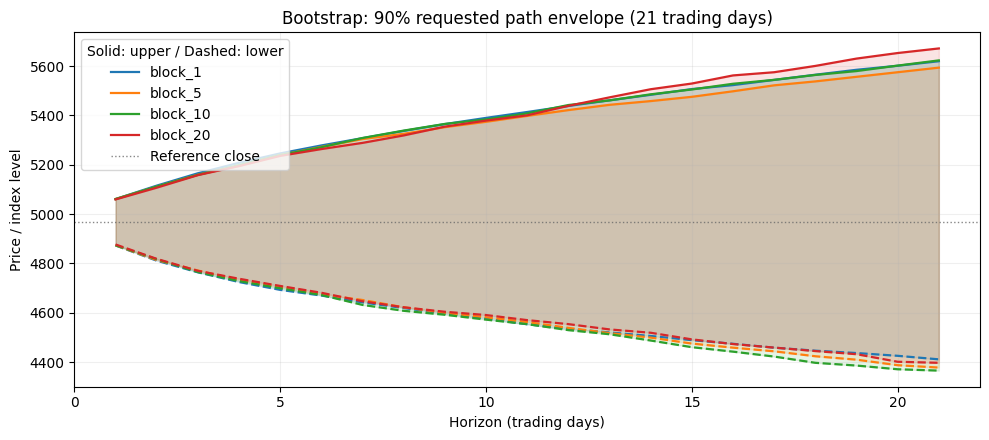

In [42]:
bootstrap.plot_extreme_range(probability=0.9)

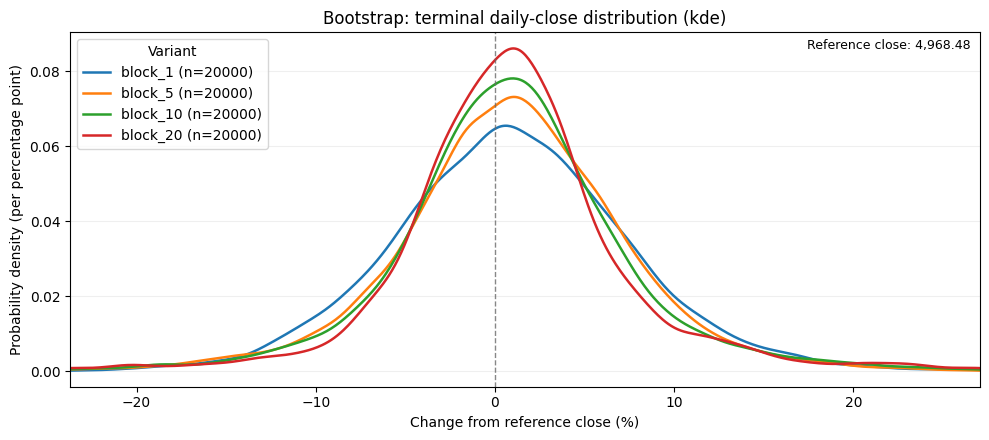

In [43]:
bootstrap.plot_price_distribution(kind='kde')

In [44]:
bootstrap.recovery_after_decline(decline_pct=10)

as_of_date 2026-11-17, reference_price 4968, horizon_days 21


,horizon_days,decline_pct,recovery_pct,n_paths,decline_paths,recovered_paths,decline_probability_pct,recovery_probability_pct,median_recovery_days,status,warning
variant,,,,,,,,,,,
block_1,21,10.0%,0.0%,20000,1495,15,7.5%,1.0%,8.0,ok,—
block_5,21,10.0%,0.0%,20000,1475,72,7.4%,4.9%,6.0,ok,—
block_10,21,10.0%,0.0%,20000,1547,141,7.7%,9.1%,6.0,ok,—
block_20,21,10.0%,0.0%,20000,1304,151,6.5%,11.6%,10.0,ok,—


## 4. Conditional empirical analysis — current-state and fixed-value criteria

Select historical starting dates using indicators calculated **only from closing prices available at each starting date**. `AsOfCriterion` uses the indicator value measured at `as_of_date`, while `FixedValueCriterion` uses a user-specified reference value independent of `as_of_date`. Both can be combined in `conditional_empirical()` using logical AND.

- `match="within"` (default) selects values within the tolerance band. The default `tolerance_mode="relative"` uses `tolerance × abs(reference)`; `"absolute"` uses a direct difference in indicator units.
- `match="above"` and `match="below"` require **no tolerance** and compare historical values to the reference inclusively.
- `within` with a **zero reference** and relative tolerance raises `ValueError`; use `tolerance_mode="absolute"` to match a range around zero.
- `indicator_range_position(window)` measures the current close's position within the trailing high–low closing-price range: 0 = trailing low, 1 = trailing high. Constant-price windows produce NaN. The indicator's `window` is distinct from the **future** `horizon_days`.

Each historical forward path must finish by `as_of_date`. Nearby matching dates may belong to the same market episode, so `n_paths` does not necessarily represent independent evidence. Inspect effective reference values and bounds in `summary()`, or matched indicator values through `observed_paths()`.

**Adding another indicator:** Define `indicator_<name>(window)` on `PriceTargetAnalysis` (or a subclass), returning a Series aligned with the price index. Either criterion type can then use it without changes to the conditional filtering logic.

In [106]:
vol_cri = AsOfCriterion("volatility", 21, match='above')
down_cri = AsOfCriterion("drawdown", 21, match='below')
pos_cri = FixedValueCriterion("range_position", 252*3, value=0.1, match='below')

In [107]:
# Match historical market states to the indicator at as_of_date.
regimes = analysis.conditional_empirical(
    history_start=history_start,
    variants={
        'vol': [vol_cri],
        'down' : [down_cri],
        'position': [pos_cri],
        'vol_position': [vol_cri, pos_cri],
        'down_position': [down_cri, pos_cri],
        'all': [vol_cri, down_cri, pos_cri],
    },
        # Optionally combine with other conditions (AND):
        #AsOfCriterion("volatility", 21, tolerance=0.10),
        #AsOfCriterion("volatility", 21,  match='above'),
        #FixedValueCriterion("volatility", 21, value=0.5, match='above'),
        #AsOfCriterion("drawdown", 21, match='below'),
        #FixedValueCriterion("range_position", 252*2, value=0.1, match='below'),
        #FixedValueCriterion("range_position", 252*2, value=0.9, match='above'),
    sampling_step=1,
    min_history_days=252,
    min_samples=1,
    min_distinct_episodes=2,
    episode_gap_days=5,
)
regimes.summary()

,status,n_paths,as_of_date,reference_price,horizon_days,history_start,min_samples,min_history_days,min_distinct_episodes,episode_gap_days,...,lower_bound_drawdown_21,upper_bound_drawdown_21,current_range_position_756,reference_range_position_756,reference_source_range_position_756,match_range_position_756,tolerance_range_position_756,tolerance_mode_range_position_756,lower_bound_range_position_756,upper_bound_range_position_756
variant,,,,,,,,,,,,,,,,,,,,,
vol,ok,175,2026-11-17,4968,21,2001-01-01,1,252,2,5,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
down,ok,72,2026-11-17,4968,21,2001-01-01,1,252,2,5,...,NaN,-0.173633,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
position,ok,57,2026-11-17,4968,21,2001-01-01,1,252,2,5,...,NaN,NaN,0.393544,0.1,fixed_value,below,NaN,NaN,NaN,0.1
vol_position,ok,21,2026-11-17,4968,21,2001-01-01,1,252,2,5,...,NaN,NaN,0.393544,0.1,fixed_value,below,NaN,NaN,NaN,0.1
down_position,ok,20,2026-11-17,4968,21,2001-01-01,1,252,2,5,...,NaN,-0.173633,0.393544,0.1,fixed_value,below,NaN,NaN,NaN,0.1
all,ok,13,2026-11-17,4968,21,2001-01-01,1,252,2,5,...,NaN,-0.173633,0.393544,0.1,fixed_value,below,NaN,NaN,NaN,0.1


In [108]:
kw = dict(
    thresholds=[-10, -5, 5, 10], pct=True
)
regimes.threshold_probabilities(mode="mixed", **kw)

as_of_date 2026-11-17, reference_price 4968, horizon_days 21


,<-10%,<-5%,≥+5%,≥+10%
variant,,,,
vol,16.0%,20.0%,49.1%,34.3%
down,12.5%,19.4%,37.5%,30.6%
position,7.0%,12.3%,61.4%,29.8%
vol_position,19.0%,23.8%,57.1%,47.6%
down_position,20.0%,25.0%,45.0%,35.0%
all,30.8%,38.5%,30.8%,23.1%


In [90]:
# `price_type='min', mode='below'` reports whether the *lowest future daily close* breached the specified downside thresholds.
regimes.threshold_probabilities(mode="below", price_type="min", **kw)

as_of_date 2026-11-17, reference_price 4968, horizon_days 21


,<-10%,<-5%,<+5%,<+10%
variant,,,,
vol,32.0%,48.0%,98.3%,99.4%
down,41.7%,55.6%,95.8%,98.6%
position,22.8%,33.3%,96.5%,100.0%
vol_position,28.6%,42.9%,95.2%,100.0%
down_position,50.0%,65.0%,95.0%,100.0%
all,46.2%,53.8%,92.3%,100.0%


In [91]:
regimes.return_quantiles(probabilities=[0.1, 0.25, 0.5, 0.75, 0.9])

as_of_date 2026-11-17, reference_price 4968, horizon_days 21


,p10,p25,p50,p75,p90
variant,,,,,
vol,-15.8%,-2.5%,+4.9%,+13.3%,+21.2%
down,-10.3%,-4.3%,+2.6%,+12.6%,+18.8%
position,-7.2%,+2.9%,+6.5%,+14.7%,+20.1%
vol_position,-14.2%,-4.4%,+9.8%,+16.8%,+22.0%
down_position,-14.3%,-5.5%,+3.6%,+18.5%,+24.8%
all,-14.8%,-10.3%,+3.1%,+9.8%,+23.2%


In [94]:
regimes.extreme_range(probability=0.9, horizons=[5])

as_of_date 2026-11-17, reference_price 4968, horizon_days 21


,variant,horizon_days,probability,lower_price,upper_price,empirical_coverage,n_paths,status,warning
0,vol,5,0.9,4200.560102,5698.494214,0.908571,175,ok,None
1,down,5,0.9,3948.174640,5860.904834,0.916667,72,ok,None
2,position,5,0.9,3948.174640,5891.042715,0.929825,57,ok,None
3,vol_position,5,0.9,3899.473790,5927.213692,0.904762,21,ok,None
4,down_position,5,0.9,3899.473790,5927.213692,0.900000,20,ok,None
5,all,5,0.9,3862.243071,6058.246509,1.000000,13,ok,None


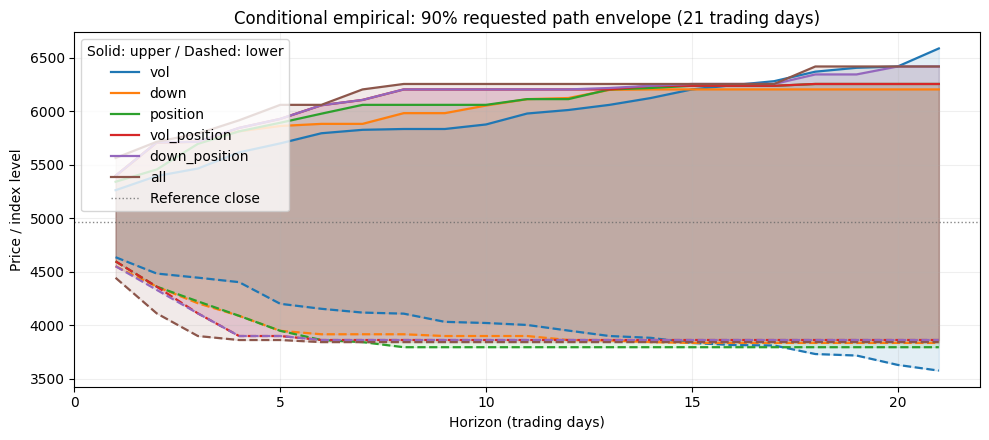

In [95]:
regimes.plot_extreme_range(probability=0.9)

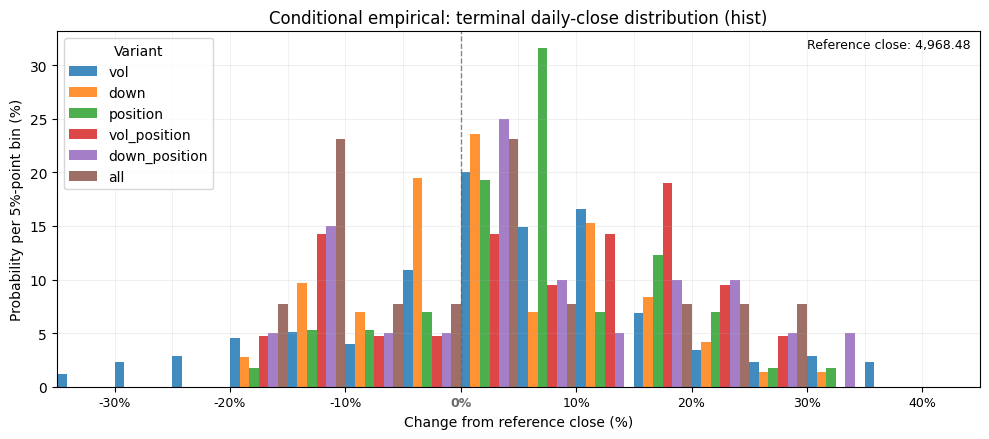

In [96]:
regimes.plot_price_distribution(bin_width_pct=5)

In [97]:
regimes.recovery_after_decline(decline_pct=10)

as_of_date 2026-11-17, reference_price 4968, horizon_days 21


,horizon_days,decline_pct,recovery_pct,n_paths,decline_paths,recovered_paths,decline_probability_pct,recovery_probability_pct,median_recovery_days,status,warning
variant,,,,,,,,,,,
vol,21,10.0%,0.0%,175,56,19,32.0%,33.9%,11.0,ok,—
down,21,10.0%,0.0%,72,30,14,41.7%,46.7%,11.5,ok,—
position,21,10.0%,0.0%,57,13,7,22.8%,53.8%,7.0,ok,—
vol_position,21,10.0%,0.0%,21,6,3,28.6%,50.0%,7.0,ok,—
down_position,21,10.0%,0.0%,20,10,7,50.0%,70.0%,7.0,ok,—
all,21,10.0%,0.0%,13,6,3,46.2%,50.0%,7.0,ok,—


## 6. Cross-Method Comparison — Interpretation and Limitations

Compare `threshold_probabilities()`, `return_quantiles()`, `recovery_after_decline()` and `extreme_range()` across the four methods using common event definitions and horizons. The two new result methods return DataFrames with `styled=False` and pandas Stylers with `styled=True` (default); no additional simulations or plots are required.

**Differences between methods reflect different assumptions, not necessarily differences in predictive accuracy.** Normal serves as a zero-log-drift volatility baseline, while Empirical, Bootstrap, and  differ in historical sampling, drift treatment, and path dependence.

Historical paths may overlap, and  may rely on relatively few distinct episodes. Consequently, sample counts do not necessarily represent independent observations.

The comparison provides **model-conditional risk estimates**, not calibrated real-world probabilities. Interpret differences in light of each method's assumptions and sample limitations.

In [110]:
# Generate four methods once; analysis paths are reused by comparison tables.
comparison = ModelComparison(
    prices,
    horizon_days=horizon_days,
    history_start=history_start,
    sampling_step=1,
    simulations=20_000,
    random_seed=42,
    normal={"lookback_days": (20, 60, 120)},
    empirical={},
    bootstrap={
        "block_sizes": (1, 5, 10, 20),
        "drift_adjustment": "none",
    },
    conditional_empirical={
        "variants": [vol_cri, down_cri, pos_cri],
        "min_samples": 1,
        "min_distinct_episodes": 2,
        "episode_gap_days": 5,
    },
)

In [111]:
# Access individual analysis results.
comparison.results["conditional_empirical"].summary()

,status,n_paths,as_of_date,reference_price,horizon_days,history_start,min_samples,min_history_days,min_distinct_episodes,episode_gap_days,...,reference_range_position_756,reference_source_range_position_756,match_range_position_756,tolerance_range_position_756,tolerance_mode_range_position_756,lower_bound_range_position_756,upper_bound_range_position_756,criteria,matched_dates,distinct_episodes
variant,,,,,,,,,,,,,,,,,,,,,
matched,ok,13,2026-11-17,4968,21,2001-01-01,1,252,2,5,...,0.1,fixed_value,below,None,None,None,0.1,"[{'indicator': 'volatility_21', 'reference_sou...",13,3


In [112]:
# 1. Compare threshold probabilities.
kw = dict(
    thresholds = [-10, -5, 5, 10], # [-2, -1, 1, 2], #[-5, -2, 2, 5], #
    mode="mixed",
    pct=True,
    price_type="terminal"
)
comparison.threshold_probabilities(**kw)

In [113]:
# Compare return quantiles across the four previously generated methods.
comparison.return_quantiles(
    probabilities=[0.10, 0.25, 0.50, 0.75, 0.90],
    price_type="terminal",
    styled=True,
)

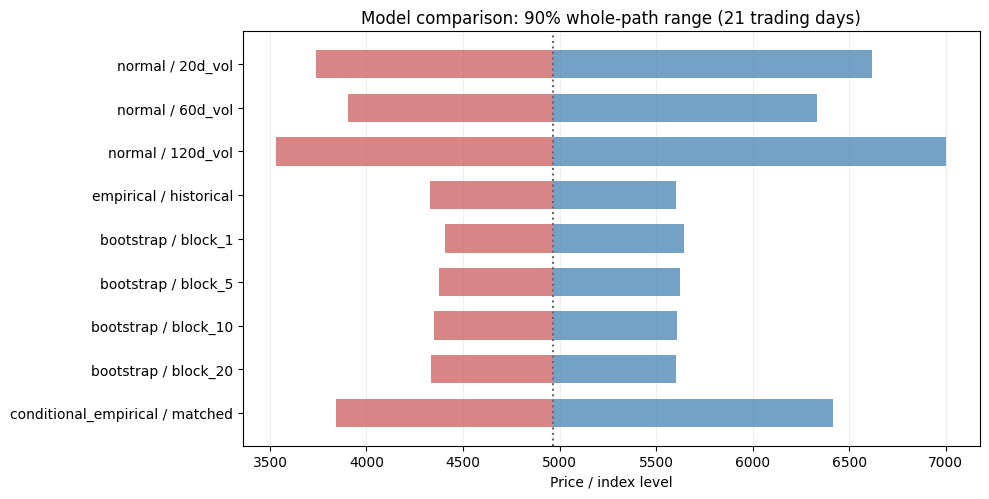

In [114]:
# 2. Compare whole-path extreme ranges.
comparison.extreme_range(probability=0.90, plot=True)

In [115]:
# Compare post-decline recovery frequencies and median recovery times.
comparison.recovery_after_decline(
    decline_pct=10,
    recovery_pct=0,
    styled=True,
)

## Interpretation and limitations

- `threshold_probabilities()` returns *cumulative event probabilities*: they are **not** mutually exclusive, and columns need not sum to 100%. For `mode='mixed'`, negative return thresholds test `<` and zero/positive return thresholds test `≥`. `mode='above'` and `mode='below'` use one comparator for all thresholds.
- `price_type='terminal'` evaluates the H-th future daily close; `min` and `max` evaluate the lowest and highest **future daily close** through that horizon. `min/below` and `max/above` are daily-close barrier-event tests, not intraday touches.
- `extreme_range()` uses conservative equal-tail order statistics of path minima and maxima. `empirical_coverage` reports the fraction of generated/observed paths that stayed between both boundaries throughout the chosen interval. These are not terminal-only confidence intervals or verified out-of-sample guarantees.
- Normal is a **volatility-sensitivity baseline**: compare a fixed loss threshold or a fixed-coverage whole-path range across 20/60/120-day volatility estimates. Similar probabilities for equal-sized upside and downside targets are primarily an implication of the zero-log-drift model, **not empirical evidence** of similar market prospects. A price-domain upper envelope can be farther from today's price than the lower one without implying bullish drift. Historical lookback variants are overlapping sensitivity assumptions, not independent predictive models.
- Normal/bootstrap estimates reflect Monte Carlo paths. Empirical/similar-regime percentages are historical sample frequencies with potentially overlapping, dependent windows; path count is not the number of independent market events.
- All results require correct, complete daily closing-price data. Verify splits, data adjustment, stale quotations, dividends and distributions.

### Optional threshold-event backtest

The backtest uses the **same event** as `threshold_probabilities()`. The example below evaluates the event that the terminal close is strictly below -10%; it is not the old touch-only backtest. Use walk-forward anchor dates with the specified model's historical information and check the number of valid forecasts.

```python
bt = analysis.backtest(
    method="normal", threshold=-10, pct=True, mode="below",
    price_type="terminal", variant="60d_vol",
    method_kwargs={"lookback_days": [60], "simulations": 2_000},
    test_start="2020-01-01", step_days=63,
)
bt.summary()
```

This backtest is optional and intentionally not executed automatically in the notebook. Its Brier score is a descriptive diagnostic; overlapping test windows, limited test dates and the selected model assumptions constrain inference. Return quantiles and descriptive post-decline recovery statistics are implemented above. Loss Severity/Expected Shortfall and gain-reversal analysis are deferred; recovery-day medians include only paths that recovered within the observation horizon, not right-censoring-adjusted estimates.